# Gold strategy search: 7,488 variants against your funded-account rules

Question: among a large set of known intraday ideas, is there one that reliably makes money on
XAUUSD after costs, or that passes the weekly funded challenge (+600 USD before losing 200 in a
day or 400 in the week) better than luck?

**Universe.** 38 strategy families, 76 entry rules (trend following, breakouts, mean reversion,
session-average price, RSI(2), squeezes, previous-day levels, Asian range, opening ranges in
London and New York, time-of-day drift, intraday momentum), each tested in 4 session windows
where relevant, with and without a daily trend filter, and with 18 exit settings
(stop 1.5, 3 or 5 ATR; target 1, 2 or 3 times the risk; maximum hold 1 or 4 hours).
That gives 7,488 strategies.

**Method.**
* Signals on 5-minute bars, filled at the next 1-minute open; exits resolved on 1-minute bars.
* Costs: 0.30 spread and 0.10 slippage per trade. One position at a time, at most 2 trades per day, flat by 16:45 New York.
* Selection on 2022-2024 only (in-sample). 2025-2026 is the untouched holdout (out-of-sample).
* Luck controls: the same universe with **random directions** (same entry times and exits),
  the same universe **without costs**, and White's Reality Check / Hansen's SPA test on the
  best in-sample strategy.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import search as S
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
U = S.build_universe(); D = U["D"]
cat, tr = S.run_all(U)
_, trr = S.run_all(U, random_dirs=True, seed=7)
_, tr0 = S.run_all(U, spread=0.0, slip=0.0)
st, sr, s0 = (S.stats(cat, x, D) for x in (tr, trr, tr0))
ok = (st.n_is >= 100).to_numpy()
print(f"{len(cat)} strategies, {cat.rule.nunique()} entry rules, {cat.family.nunique()} families; "
      f"{ok.sum()} with at least 100 in-sample trades")

7488 strategies, 76 entry rules, 38 families; 7428 with at least 100 in-sample trades


## 1. Real strategies versus random entries
If the rules had skill, the real distribution of in-sample t-statistics would sit to the right of the random-direction one.

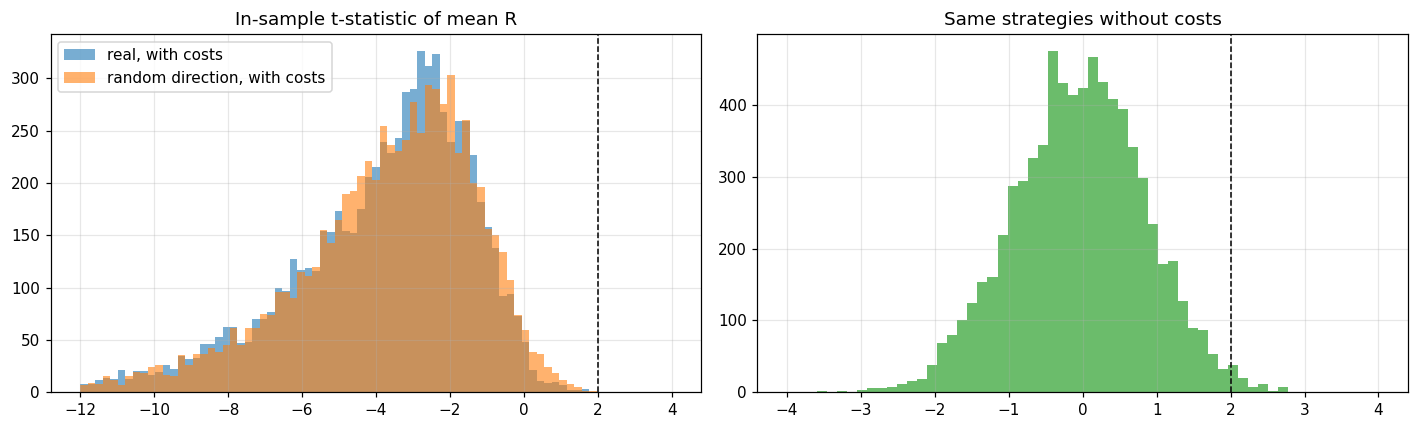

,real,random direction,"real, no costs"
mean R in-sample,-0.144,-0.140,-0.001
median t,-3.362,-3.341,-0.034
best t,1.737,1.776,2.950
share with t > 2,0.000,0.000,0.010
positive in both periods (t > 1),3.000,4.000,210.000


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(-12, 4, 80)
ax[0].hist(st.t_is[ok], bins, alpha=.6, label="real, with costs")
ax[0].hist(sr.t_is[ok], bins, alpha=.6, label="random direction, with costs")
ax[0].axvline(2, color="k", ls="--", lw=1); ax[0].set_title("In-sample t-statistic of mean R"); ax[0].legend()
ax[1].hist(s0.t_is[ok], np.linspace(-4, 4, 60), alpha=.7, color="C2")
ax[1].axvline(2, color="k", ls="--", lw=1); ax[1].set_title("Same strategies without costs")
plt.tight_layout(); plt.show()
tab = pd.DataFrame({k: {"mean R in-sample": s.r_is[ok].mean(), "median t": s.t_is[ok].median(),
                        "best t": s.t_is[ok].max(), "share with t > 2": (s.t_is[ok] > 2).mean(),
                        "positive in both periods (t > 1)": int(((s.t_is > 1) & (s.t_oos > 1))[ok].sum())}
                    for k, s in [("real", st), ("random direction", sr), ("real, no costs", s0)]})
tab.round(3)

Reading: with costs, the real strategies and the random-direction strategies are almost the same
distribution (average about -0.14 R per trade, which is simply the cost). Without costs the real
strategies are centred on zero and only 1% reach t > 2, less than the 2.5% that pure chance
gives. Only 3 real strategies are positive with t > 1 in both periods, against 4 for random directions.

## 2. Does in-sample performance predict the holdout?

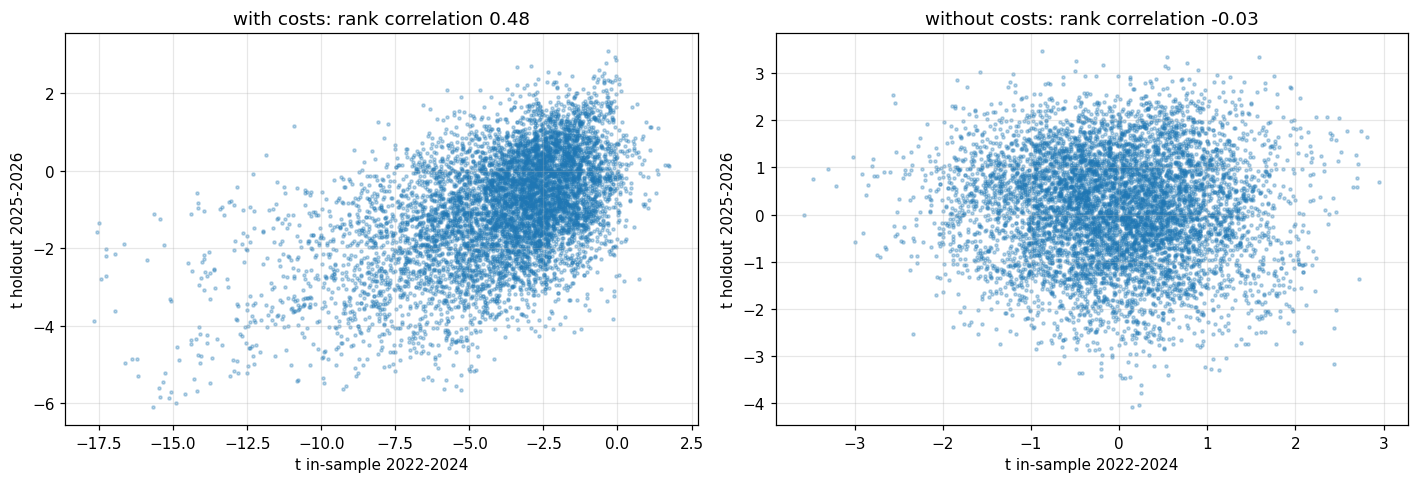

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, s, ttl in [(ax[0], st, "with costs"), (ax[1], s0, "without costs")]:
    q = s[ok]
    a.scatter(q.t_is, q.t_oos, s=4, alpha=.3)
    rho = q[["t_is", "t_oos"]].corr("spearman").iloc[0, 1]
    a.set_xlabel("t in-sample 2022-2024"); a.set_ylabel("t holdout 2025-2026")
    a.set_title(f"{ttl}: rank correlation {rho:.2f}")
plt.tight_layout(); plt.show()

With costs the correlation is positive only because frequent, tight-stop strategies lose to costs
in both periods. Without costs it is about zero: being good in 2022-2024 says nothing about 2025-2026.

## 3. Luck-adjusted test of the best strategy (Reality Check / SPA)

In [4]:
nd = D.day_id.max() + 1
day_oos = np.zeros(nd, bool); day_oos[D.day_id[D.oos]] = True
idx = np.flatnonzero(ok)
for name, T in [("with costs", tr), ("without costs", tr0)]:
    M = S.daily_matrix([T[i] for i in idx], D, ~day_oos)
    best, Tst, rc, spa = S.reality_check(M, n_boot=500)
    r = cat.iloc[idx[best]]
    print(f"{name}: best = {r.rule} / {r.session} / {r['filter']} / stop {r.sl_atr} ATR / {r.rr}R / {r.hold} min, "
          f"t = {Tst:.2f}, Reality Check p = {rc:.2f}, SPA p = {spa:.2f}")

with costs: best = orb_eq_60 / fixed / trend / stop 5.0 ATR / 1.0R / 240 min, t = 1.73, Reality Check p = 1.00, SPA p = 1.00


without costs: best = orb_eq_60 / fixed / trend / stop 5.0 ATR / 1.0R / 240 min, t = 2.92, Reality Check p = 0.92, SPA p = 0.92


A p-value near 1 means the best of 7,488 strategies is exactly as good as the best of 7,488 coin flips.

## 4. Best family results and the few consistent candidates

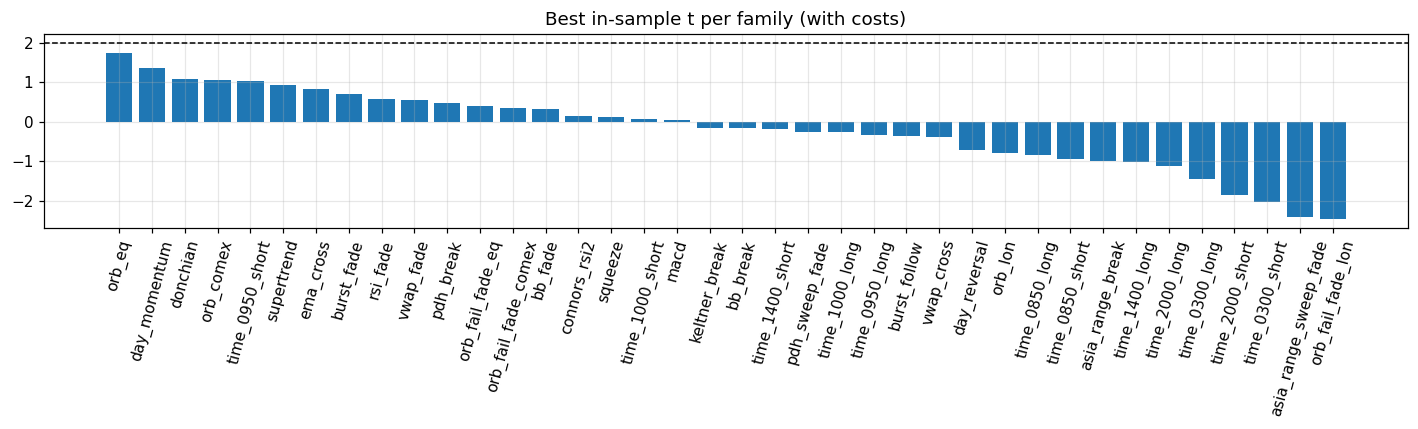

,rule,session,filter,sl_atr,rr,hold,n_is,r_is,t_is,n_oos,r_oos,t_oos
119,ema_cross_9_21,ny,trend,3.0,3.0,240,694,0.043,0.839,448,0.047,0.815
1275,donchian_288,ny,trend,5.0,2.0,240,271,0.059,0.969,158,0.090,1.273
1277,donchian_288,ny,trend,5.0,3.0,240,261,0.073,1.094,151,0.082,1.130
7375,day_momentum_12,fixed,trend,5.0,1.0,240,329,0.026,0.851,244,0.033,0.897
7377,day_momentum_12,fixed,trend,5.0,2.0,240,329,0.038,1.117,244,0.044,1.122
7379,day_momentum_12,fixed,trend,5.0,3.0,240,329,0.049,1.367,244,0.044,1.115


In [5]:
fam = (st[ok].groupby("family").agg(variants=("t_is", "size"), best_t_is=("t_is", "max"),
                                   mean_r_is=("r_is", "mean"), mean_r_oos=("r_oos", "mean"))
          .sort_values("best_t_is", ascending=False))
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(fam.index, fam.best_t_is); ax.axhline(2, color="k", ls="--", lw=1)
ax.set_title("Best in-sample t per family (with costs)"); plt.xticks(rotation=75); plt.tight_layout(); plt.show()
cols = ["rule", "session", "filter", "sl_atr", "rr", "hold", "n_is", "r_is", "t_is", "n_oos", "r_oos", "t_oos"]
st[ok & (st.t_is > 0.8) & (st.t_oos > 0.8)][cols].round(3)

The few strategies that are positive in both periods (the 12:00 intraday momentum rule, the
24-hour Donchian break in New York, a 9/21 EMA cross in New York, all with the daily trend
filter and wide stops) all earn about +0.04 to
+0.09 R per trade with t near 1: the same thin edge as the ORB we automated, and no better than
the random-direction control produces by chance.

## 5. The weekly funded challenge: pass rate versus luck

Each week is treated as a fresh first week: trades stop at +600, no trade may push the day below
-200 or the week below -400 (with a 15 USD buffer). We vary the risk per trade.

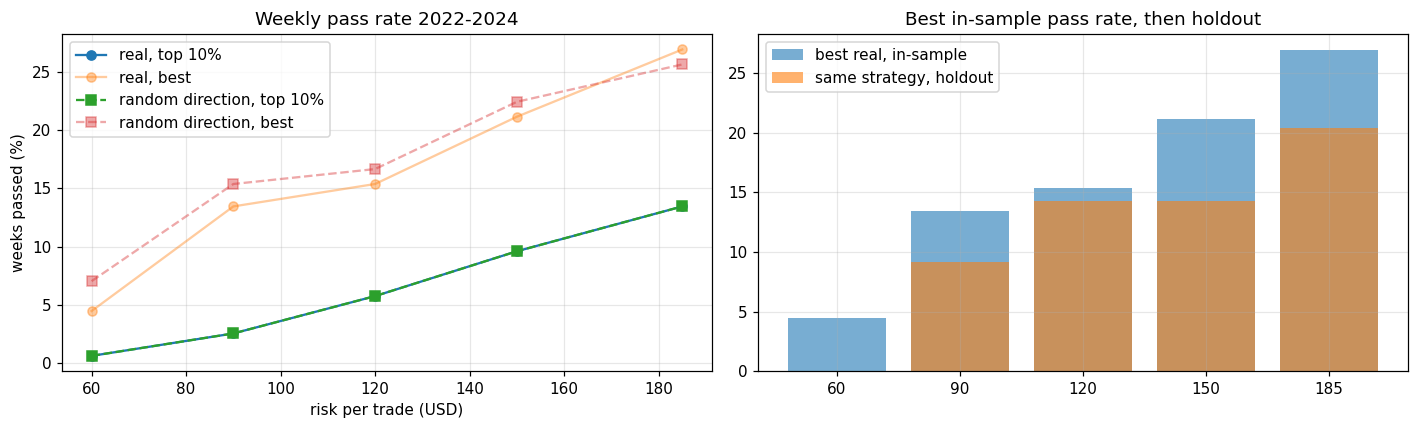

median_pass  best_pass  q90_pass  median_breach
risk kind                                                             
60   random direction          0.0        7.1       0.6            0.0
     real                      0.0        4.5       0.6            0.0
90   random direction          0.0       15.4       2.6            0.0
     real                      0.0       13.5       2.6            0.4
120  random direction          0.6       16.7       5.8            0.4
     real                      0.6       15.4       5.8            0.4
150  random direction          1.9       22.4       9.6            0.4
     real                      1.9       21.2       9.6            0.4
185  random direction          3.8       25.6      13.5            2.0
     real                      3.8       26.9      13.5            2.0

In [6]:
wk_id, _ = S.week_index(D)
w_oos = np.zeros(wk_id.max() + 1, bool); w_oos[wk_id[D.oos]] = True
rows = []
for risk in [60, 90, 120, 150, 185]:
    for kind, T in [("real", tr), ("random direction", trr)]:
        for q in idx:
            p, br = S.challenge(*T[q], D, wk_id, risk)
            rows.append((kind, q, risk, p[~w_oos].mean(), p[w_oos].mean(), br.mean()))
ch = pd.DataFrame(rows, columns=["kind", "q", "risk", "pass_is", "pass_oos", "breach"])
g = ch.groupby(["risk", "kind"]).agg(median_pass=("pass_is", "median"), best_pass=("pass_is", "max"),
                                    q90_pass=("pass_is", lambda x: x.quantile(.9)), median_breach=("breach", "median"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for kind, m in [("real", "o-"), ("random direction", "s--")]:
    x = g.xs(kind, level="kind")
    ax[0].plot(x.index, x.q90_pass * 100, m, label=f"{kind}, top 10%")
    ax[0].plot(x.index, x.best_pass * 100, m, alpha=.4, label=f"{kind}, best")
ax[0].set_xlabel("risk per trade (USD)"); ax[0].set_ylabel("weeks passed (%)"); ax[0].legend(); ax[0].set_title("Weekly pass rate 2022-2024")
best = ch[ch.kind == "real"].sort_values("pass_is").groupby("risk").tail(1)
ax[1].bar(best.risk.astype(str), best.pass_is * 100, alpha=.6, label="best real, in-sample")
ax[1].bar(best.risk.astype(str), best.pass_oos * 100, alpha=.6, label="same strategy, holdout")
ax[1].set_title("Best in-sample pass rate, then holdout"); ax[1].legend()
plt.tight_layout(); plt.show()
(g * 100).round(1)

Reading: the pass rate is driven almost entirely by the **size of the bet and the shape of the
payoff** (wide 3R targets, risk close to the daily limit), not by the strategy. Random
directions reach the same pass rates as the real rules at every size. At 185 USD risk the best
variants pass about a quarter of weeks, but random entries do too, and the breach rate rises
because a single bad fill can exceed the daily limit.

## Conclusions

* 7,488 strategy variants from 38 families were tested with realistic costs on 5 years of 1-minute data.
* **No strategy shows an edge that survives the luck controls.** Real rules look like random entries
  with costs (Reality Check p about 1.0 with costs, about 0.9 without).
* Without costs, the rules are centred on zero: the market gives these public ideas nothing on gold intraday.
* The handful of consistent strategies (12:00 momentum, New York Donchian) earn about +0.05 R per trade, the
  same thin edge we already automated, and random controls produce as many such cases.
* The +600 week is a sizing and variance question: with no edge, the best achievable weekly pass rate
  is about 20 to 30% with near-maximum risk and wide targets, and it carries a real breach risk and a
  negative expected value. No indicator changes that.
* What could change it: a genuinely different information source (order flow, futures volume, news
  timing, cross-asset signals such as real yields and the dollar), tested the same way.